In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.ensemble import RandomForestRegressor

In [2]:
df= pd.read_csv("/Users/tam_pr/research/eda/data_processing/cleaned_df.csv")

In [3]:
df.head()

,MW,MCN,Mce,Mla,AWCe,AWLa,CP,CS,BG,ZP,...,Ce,La,Conc,AA,group_id,Material_CL1,Material_CL10,Material_CL5,Method_DPPH,Method_H2O2
0,172.1148,0.01162,0.01162,0.0,5.045702,0.0,0.528725,8.957388,3.1,39.04,...,26.742845,0.0,5,41.142363,5,0,0,0,1,0
1,172.1148,0.01162,0.01162,0.0,5.045702,0.0,0.528725,8.957388,3.1,39.04,...,26.742845,0.0,5,41.077538,5,0,0,0,1,0
2,172.1148,0.01162,0.01162,0.0,5.045702,0.0,0.528725,8.957388,3.1,39.04,...,26.742845,0.0,20,58.634350,6,0,0,0,1,0
3,172.1148,0.01162,0.01162,0.0,5.045702,0.0,0.528725,8.957388,3.1,39.04,...,26.742845,0.0,20,58.439875,6,0,0,0,1,0
4,172.1148,0.01162,0.01162,0.0,5.045702,0.0,0.528725,8.957388,3.1,39.04,...,26.742845,0.0,20,58.688371,6,0,0,0,1,0


In [4]:
df.shape

(175, 26)

In [5]:
df.dtypes

MW               float64
MCN              float64
Mce              float64
Mla              float64
AWCe             float64
AWLa             float64
CP               float64
CS               float64
BG               float64
ZP               float64
DLS                int64
CC               float64
CO               float64
COO              float64
O1               float64
O2               float64
Ce               float64
La               float64
Conc               int64
AA               float64
group_id           int64
Material_CL1       int64
Material_CL10      int64
Material_CL5       int64
Method_DPPH        int64
Method_H2O2        int64
dtype: object

#### After checking the data was properly migrated from the EDA file, we declare X and Y, X being our features or modeling variables and Y being our target variable
#### Before choosing a regression model for predicting Y we must perform a feature selection by importance, and to be able to do that we will split our data into Test and Train sets, using the group_id variable as guidelines to prevent a possible data leak

In [6]:
X= df.copy()

In [7]:
X.drop(columns=["group_id","AA"], inplace=True)

In [8]:
y = df["AA"].copy()

In [9]:
X.shape

(175, 24)

In [10]:
y.shape

(175,)

#### Group Shuffle Split

In [11]:
splitter = GroupShuffleSplit(n_splits=1, test_size= 0.2, random_state= 1234)

In [12]:
train_indices, test_indices = next(splitter.split(X = X, y = y, groups = df["group_id"]))

In [13]:
X_train , X_test = X.iloc[train_indices], X.iloc[test_indices]

In [14]:
y_train , y_test = y.iloc[train_indices], y.iloc[test_indices]

#### After splitting our data we just quickly check the shape of both the X splits and the y splits

In [15]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(139, 24)
(36, 24)
(139,)
(36,)


#### Everything matches, now we can move onto the next step

#### Feature importance and feature selection 
#### We will use SelectKBest to identify which features are actually useful for modeling 

In [16]:
feature_selector = SelectKBest(score_func=f_regression, k=10)

In [17]:
feature_selector.fit(X_train,y_train)

SelectKBest(score_func=<function f_regression at 0x115d26090>)

In [18]:
f_scores = pd.Series(feature_selector.scores_,index= X_train.columns).sort_values(ascending=True)
f_scores

Material_CL5      4.571939
Conc              5.607912
Method_DPPH       5.797529
Material_CL1      8.761539
DLS              18.213802
CP               19.839294
CC               26.534872
COO              31.959304
Ce               37.948399
O2               39.315646
Method_H2O2      39.407575
BG               42.114659
Material_CL10    43.913606
O1               47.315424
CO               54.603334
La               84.596755
MCN              85.245361
Mce              85.245362
AWLa             85.245362
AWCe             85.245362
Mla              85.245362
MW               85.254825
ZP               86.451700
CS               87.896669
dtype: float64

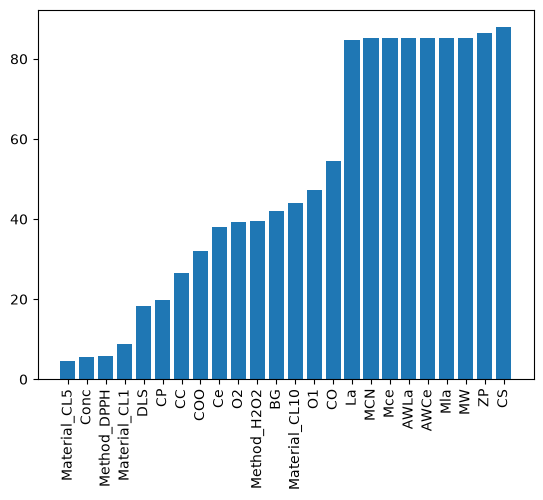

In [19]:
plt.bar(f_scores.index, f_scores)
plt.xticks(rotation=90)
plt.show()

#### According to SelectKBest, the optimal number of features is 10, but through the graph we can see that all the chosen features sit at around 84-87, except the variable "CO" which sits at 54.603334, picking it might seem non-sensical but thats why we will perform an Adjusted R^2 sweep to validate the results of SelectKBest, which will take into account how the variables interact with each other rather than checking for isolated relation with "AA"

In [20]:
sorted_f_scores = pd.Series(feature_selector.scores_,index= X_train.columns).sort_values(ascending=False)
sorted_f_scores

CS               87.896669
ZP               86.451700
MW               85.254825
Mla              85.245362
AWCe             85.245362
AWLa             85.245362
Mce              85.245362
MCN              85.245361
La               84.596755
CO               54.603334
O1               47.315424
Material_CL10    43.913606
BG               42.114659
Method_H2O2      39.407575
O2               39.315646
Ce               37.948399
COO              31.959304
CC               26.534872
CP               19.839294
DLS              18.213802
Material_CL1      8.761539
Method_DPPH       5.797529
Conc              5.607912
Material_CL5      4.571939
dtype: float64

In [21]:
sorted_f_scores.size

24

In [22]:
X_train_copy = X_train.copy()
X_test_copy = X_test.copy()

adj_r2_score = []

sorted_index_list = sorted_f_scores.index.tolist()

def adj_r_sq(r_sq, n, p): 
    adj_r = 1 - ((1- r_sq)*(n-1)/(n-p-1))
    return adj_r

n = len(y_test)

for i in range (len(sorted_index_list)): 
    regressor = RandomForestRegressor(random_state=1234)
    regressor.fit(X_train_copy,y_train)
    r_sq = regressor.score(X_test_copy,y_test) #regular r^2
    p = len(sorted_index_list)

    adj_r = adj_r_sq(r_sq, n, p)
    
    adj_r2_score.append(adj_r)

    sorted_index_list.pop()

    X_train_copy = X_train_copy[sorted_index_list]
    X_test_copy = X_test_copy[sorted_index_list]
    

In [23]:
n_features = list(range(24, 0, -1))


In [24]:
results_table =  pd.DataFrame({
    'Number of features': n_features,
    'Adj R^2': adj_r2_score
})
results_table

,Number of features,Adj R^2
0,24,-0.530590
1,23,-0.408457
2,22,-0.198100
3,21,-2.892536
4,20,-2.633033
5,19,-2.405969
6,18,-2.205618
7,17,-2.027528
8,16,-1.868184
9,15,-1.724775


#### Couldnt find strong enough evidence to support the claim that k = 10 is the most optimal number of features through a single fold Adj R^2 sweep, the data gotten through computing the Adjusted R^2 value through an itterative loop with decreasing features in order of the gotten f-score, could be because of the small size of our training and test sets 

#### Since we couldnt find a clear justifying argument for k = 10, we will continue to modeling, but first with k = 10 and then with k = 9, to be able to compare results and finally determine whether the model performs better with k = 10 or k = 9. 

In [25]:
sorted_f_scores.index

Index(['CS', 'ZP', 'MW', 'Mla', 'AWCe', 'AWLa', 'Mce', 'MCN', 'La', 'CO', 'O1',
       'Material_CL10', 'BG', 'Method_H2O2', 'O2', 'Ce', 'COO', 'CC', 'CP',
       'DLS', 'Material_CL1', 'Method_DPPH', 'Conc', 'Material_CL5'],
      dtype='str')

In [35]:
k_10_df = df[['CS', 'ZP', 'MW', 'Mla', 'AWCe', 'AWLa', 'Mce', 'MCN', 'La', 'CO','group_id',"AA"]]

In [36]:
k_9_df = df[['CS', 'ZP', 'MW', 'Mla', 'AWCe', 'AWLa', 'Mce', 'MCN', 'La','group_id',"AA"]]

In [37]:
k_9_df

,CS,ZP,MW,Mla,AWCe,AWLa,Mce,MCN,La,group_id,AA
0,8.957388,39.04,172.1148,0.000000,5.045702,0.00000,0.011620,0.011620,0.000000,5,41.142363
1,8.957388,39.04,172.1148,0.000000,5.045702,0.00000,0.011620,0.011620,0.000000,5,41.077538
2,8.957388,39.04,172.1148,0.000000,5.045702,0.00000,0.011620,0.011620,0.000000,6,58.634350
3,8.957388,39.04,172.1148,0.000000,5.045702,0.00000,0.011620,0.011620,0.000000,6,58.439875
4,8.957388,39.04,172.1148,0.000000,5.045702,0.00000,0.011620,0.011620,0.000000,6,58.688371
...,...,...,...,...,...,...,...,...,...,...,...
170,5.687981,28.91,171.9932,0.001163,4.544342,0.50352,0.010466,0.011628,1.933542,43,84.171000
171,5.687981,28.91,171.9932,0.001163,4.544342,0.50352,0.010466,0.011628,1.933542,43,84.993000
172,5.687981,28.91,171.9932,0.001163,4.544342,0.50352,0.010466,0.011628,1.933542,44,84.805100
173,5.687981,28.91,171.9932,0.001163,4.544342,0.50352,0.010466,0.011628,1.933542,44,84.758100


In [38]:
k_10_df


,CS,ZP,MW,Mla,AWCe,AWLa,Mce,MCN,La,CO,group_id,AA
0,8.957388,39.04,172.1148,0.000000,5.045702,0.00000,0.011620,0.011620,0.000000,2.047129,5,41.142363
1,8.957388,39.04,172.1148,0.000000,5.045702,0.00000,0.011620,0.011620,0.000000,2.047129,5,41.077538
2,8.957388,39.04,172.1148,0.000000,5.045702,0.00000,0.011620,0.011620,0.000000,2.047129,6,58.634350
3,8.957388,39.04,172.1148,0.000000,5.045702,0.00000,0.011620,0.011620,0.000000,2.047129,6,58.439875
4,8.957388,39.04,172.1148,0.000000,5.045702,0.00000,0.011620,0.011620,0.000000,2.047129,6,58.688371
...,...,...,...,...,...,...,...,...,...,...,...,...
170,5.687981,28.91,171.9932,0.001163,4.544342,0.50352,0.010466,0.011628,1.933542,0.783084,43,84.171000
171,5.687981,28.91,171.9932,0.001163,4.544342,0.50352,0.010466,0.011628,1.933542,0.783084,43,84.993000
172,5.687981,28.91,171.9932,0.001163,4.544342,0.50352,0.010466,0.011628,1.933542,0.783084,44,84.805100
173,5.687981,28.91,171.9932,0.001163,4.544342,0.50352,0.010466,0.011628,1.933542,0.783084,44,84.758100


#### Now that we have both of our data frames we can now begin with testing the models, for cleanliness and the flow of work, will be exporting the csvs and 

In [ ]:
#k_9_df.to_csv("k_9_df.csv", index= False)

In [ ]:
#k_10_df.to_csv("k_10_df.csv", index= False)